# 10. E1 Lanjutan: Salah Tuduh pada 40 Potongan Tulisan Manusia

Lanjutan notebook 07 dengan data lebih banyak. Fokusnya **salah tuduh**: seberapa sering tulisan manusia dinilai AI.

- Manusia: 20 artikel The Conversation Indonesia (2017-2019, sebelum ChatGPT), masing-masing diambil 2 potongan 100-200 kata, jadi 40 teks.
- AI: 20 esai dengan judul yang sama, dibuat 2 model Groq, lalu dipotong dengan aturan yang sama.

| Detektor | Ambang sedang / tinggi |
|---|---|
| Heuristik | 42 / 70 |
| Groq gpt-oss-120b (AI sebagai juri) | 42 / 70 |
| Winston AI | 35 / 70 |

Heuristik dan Groq menilai semua 60 teks. Kredit Winston terbatas, jadi Winston menilai sebagian teks manusia dulu, dan ketiganya dibandingkan lagi pada teks yang sama itu.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import hashlib
import os
import re

import matplotlib.pyplot as plt
import pandas as pd

from src import notebook_kit as kit
from src.evaluate_baseline import bootstrap_backend

pd.set_option("display.max_colwidth", 70)

KEYS = kit.use_keys(groq_env="GROQ_API_KEY_E1")
bootstrap_backend()
from apps.analysis.engines.ai_score import score_ai_probability
from apps.analysis.engines.text_features import extract_features
from apps.analysis.providers import groq as groq_judge
from apps.analysis.providers import winston
from src import evaluate_detector, metrics

SOURCE = ROOT / "data" / "essays" / "huma_essay20.md"
DATA = ROOT / "data" / "essays" / "essays_conversation.csv"
CACHE = ROOT / "data" / "cache" / "e1_esai.jsonl"
OUT = kit.results_dir("e1_esai_conversation")

PARTS_PER_ARTICLE = 2
MIN_WORDS, MAX_WORDS = 100, 200
HUMAN_BEFORE_YEAR = 2020
WINSTON_BUDGET = 1500
GEN_MODELS = ["openai/gpt-oss-20b", "qwen/qwen3.8-27b"]
BANDS = {"heuristik": (42, 70), "groq": (42, 70), "winston": (35, 70)}

Kunci: groq ada, winston ada


## 1. Data

Setiap artikel dibersihkan dari judul bagian, kutipan orang lain, daftar bernomor, dan tautan "Baca juga". Teks lalu dipecah per kalimat dan disusun menjadi potongan 100-200 kata yang selalu berakhir di akhir kalimat. Dari tiap artikel diambil potongan awal dan potongan tengah supaya tidak tumpang tindih.

In [2]:
def parse_articles(md):
    rows = []
    for block in re.split(r"\n## (?=H\d\d · )", md)[1:]:
        head, _, body = block.partition("\n")
        article, topic = head.split(" · ", 1)
        meta = dict(re.findall(r"^- \*\*(\w[\w ]*):\*\* (.+)$", body, re.M))
        paragraphs = [p.strip() for p in body.split("\n\n")]
        kept = [p for p in paragraphs
                if p and not re.match(r"(#|>|- \*\*|Baca juga|---|\d+\. )", p) and re.search(r"[.!?…\"”)]$", p)]
        rows.append({"article": article, "topic": topic, "year": meta["Terbit"][:4], "source": meta["Sumber"],
                     "text": " ".join(re.sub(r"\s+", " ", p) for p in kept)})
    return pd.DataFrame(rows)


def chunks(text):
    sentences = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9\"“(])", text)
    out, current = [], []
    for sentence in sentences:
        if current and len(" ".join(current + [sentence]).split()) > MAX_WORDS:
            out.append(" ".join(current))
            current = []
        current.append(sentence)
        if len(" ".join(current).split()) >= MIN_WORDS:
            out.append(" ".join(current))
            current = []
    return [c for c in out if MIN_WORDS <= len(c.split()) <= MAX_WORDS]


articles = parse_articles(SOURCE.read_text())
human_rows = []
for a in articles.itertuples():
    parts = chunks(a.text)
    for n, part in enumerate([parts[0], parts[len(parts) // 2]][:PARTS_PER_ARTICLE], start=1):
        human_rows.append({"id": f"{a.article}{'ab'[n - 1]}", "article": a.article, "part": n, "label": "human",
                           "topic": a.topic, "year": a.year, "source": a.source, "generator": "", "text": part})
humans = pd.DataFrame(human_rows)
print(f"{len(articles)} artikel menjadi {len(humans)} potongan manusia")

20 artikel menjadi 40 potongan manusia


In [3]:
PROMPT = (
    'Tulis esai mahasiswa S1 berbahasa Indonesia sekitar 150 kata berjudul "{topic}". '
    "Langsung tulis isinya dalam beberapa paragraf, tanpa judul, tanpa poin-poin, tanpa kalimat pembuka untuk pembaca."
)

ai = pd.read_csv(DATA, dtype=str).query("label == 'ai'") if DATA.exists() else pd.DataFrame()
done = set(ai.article) if len(ai) else set()
new_rows = []
for i, a in enumerate(articles.itertuples()):
    if a.article in done:
        continue
    model = GEN_MODELS[i % len(GEN_MODELS)]
    text = kit.with_retry(kit.groq_chat, PROMPT.format(topic=a.topic), model, max_tokens=1024)
    new_rows.append({"id": a.article.replace("H", "A"), "article": a.article, "part": 1, "label": "ai", "topic": a.topic,
                     "year": "2026", "source": "Groq", "generator": model, "raw": text})
    print(f"{new_rows[-1]['id']} dari {model}: {len(text.split())} kata")
    pd.concat([ai, pd.DataFrame(new_rows)]).to_csv(DATA, index=False)
ai = pd.concat([ai, pd.DataFrame(new_rows)], ignore_index=True)
ai["text"] = ai.raw.map(lambda t: (chunks(re.sub(r"\s+", " ", t)) or [""])[0])

essays = pd.concat([humans, ai.drop(columns="raw")], ignore_index=True)
essays["part"] = essays.part.astype(int)
essays["words"] = essays.text.str.split().str.len()
essays["chars"] = essays.text.str.len()
essays.groupby("label").words.describe()[["count", "min", "mean", "max"]].round(0)

,count,min,mean,max
label,,,,
ai,20.0,100.0,110.0,126.0
human,40.0,100.0,111.0,130.0


In [4]:
humans = essays[essays.label == "human"]
checks = pd.Series({
    "40 potongan manusia": len(humans) == 20 * PARTS_PER_ARTICLE,
    "20 esai AI": (essays.label == "ai").sum() == 20,
    "manusia terbit sebelum 2020": pd.to_numeric(humans.year).lt(HUMAN_BEFORE_YEAR).all(),
    "sumber manusia diisi": humans.source.str.startswith("https://").all(),
    "panjang 100-200 kata": essays.words.between(MIN_WORDS, MAX_WORDS).all(),
    "tidak ada duplikat": not essays.text.duplicated().any(),
    "semua berbahasa Indonesia": essays.text.map(lambda t: extract_features(t).indonesian_ratio >= 0.05).all(),
}, name="lulus")
display(checks)
assert checks.all(), "Perbaiki data sebelum lanjut."

40 potongan manusia            True
20 esai AI                     True
manusia terbit sebelum 2020    True
sumber manusia diisi           True
panjang 100-200 kata           True
tidak ada duplikat             True
semua berbahasa Indonesia      True
Name: lulus, dtype: bool

## 2. Pengujian

Ketiga detektor memakai kode produksi. Hasil disimpan di cache yang sama dengan notebook 07, jadi jalan ulang tidak memakai kredit lagi.

Winston menilai teks berurutan: potongan awal manusia, potongan tengah manusia, lalu esai AI, sampai anggaran kredit habis.

In [5]:
cache = kit.load_jsonl(CACHE)


def cache_key(name, text):
    return f"{name}:{hashlib.sha256(text.encode()).hexdigest()[:16]}"


def cached(name, text, fn):
    key = cache_key(name, text)
    if key not in cache:
        value, seconds = kit.timed(fn, text)
        cache[key] = {**value, "seconds": round(seconds, 2)}
        kit.append_jsonl(CACHE, key, cache[key])
    return cache[key]


def run_heuristic(text):
    result = score_ai_probability(extract_features(text))
    top = sorted(result.breakdown, key=lambda s: -s.contribution)[:2]
    return {"score": result.score, "reasons": "; ".join(f"{s.label} +{s.contribution}" for s in top)}


def run_groq(text):
    raw = kit.with_retry(groq_judge.call, text, "S1")
    return {"score": round(float(raw["ai_probability"])), "reasons": "; ".join(raw.get("signals", []))}


def run_winston(text):
    probability = evaluate_detector.fetch_ai_probability(text, os.environ["WINSTON_API_KEY"], winston)
    return {"score": round(probability * 100), "reasons": ""}


DETECTORS = {"heuristik": run_heuristic, "groq": run_groq, "winston": run_winston}
active = {"heuristik": True, "groq": KEYS["groq"], "winston": KEYS["winston"]}

essays["priority"] = (essays.label == "ai") * 10 + essays.part
in_cache = essays.text.map(lambda t: cache_key("winston", t) in cache)
pending = essays[~in_cache].sort_values(["priority", "id"])
pending = pending[pending.words.cumsum() <= WINSTON_BUDGET]
winston_ids = set(essays.loc[in_cache, "id"]) | set(pending.id)
print(f"Winston: {len(winston_ids)} teks, {len(pending)} baru, sekitar {pending.words.sum()} kredit (anggaran {WINSTON_BUDGET})")

records = []
for name, fn in DETECTORS.items():
    if not active[name]:
        print(f"{name}: dilewati")
        continue
    for row in essays.itertuples():
        if name == "winston" and row.id not in winston_ids:
            continue
        try:
            records.append({"id": row.id, "label": row.label, "detector": name, **cached(name, row.text, fn)})
        except SystemExit as stop:
            print(f"{name}: berhenti. {str(stop).strip()[:120]}")
            break


def band(score, detector):
    mid, high = BANDS[detector]
    return "tinggi" if score >= high else "sedang" if score >= mid else "rendah"


scores = pd.DataFrame(records)
scores["band"] = [band(s, d) for s, d in zip(scores.score, scores.detector)]
scores.groupby(["detector", "label"]).size().unstack(fill_value=0)

Winston: 13 teks, 13 baru, sekitar 1420 kredit (anggaran 1500)


label,ai,human
detector,,
groq,20,40
heuristik,20,40
winston,0,13


## 3. Hasil

FPR adalah tulisan manusia yang dituduh AI. TPR adalah esai AI yang tertangkap. Setiap angka diberi interval Wilson 95%.

In [6]:
per_essay = (
    essays.set_index("id")[["label", "article", "words"]]
    .join(scores.pivot(index="id", columns="detector", values="score"))
    .sort_values(["label", "id"])
)


def decision_table(data):
    rows = []
    for name, group in data.groupby("detector"):
        y = (group.label == "ai").astype(int).tolist()
        for rule, threshold in (("tinggi", BANDS[name][1]), ("sedang ke atas", BANDS[name][0])):
            r = metrics.confusion_at(group.score.tolist(), y, threshold)
            n_human, n_ai = r.false_positive + r.true_negative, r.true_positive + r.false_negative
            row = {"detektor": name, "aturan": f"{rule} (skor {threshold}+)"}
            for col, hit, n in (("FPR", r.false_positive, n_human), ("TPR", r.true_positive, n_ai)):
                low, high = kit.wilson(hit, n) if n else (0, 0)
                row[col] = f"{hit}/{n} [{low:.0%}-{high:.0%}]" if n else "-"
            rows.append(row)
    return pd.DataFrame(rows)


def auc(group):
    y = (group.label == "ai").astype(int)
    return metrics.roc_auc(group.score.tolist(), y.tolist()) if y.nunique() == 2 else float("nan")


decision = decision_table(scores)
overview = pd.DataFrame({
    "auc": scores.groupby("detector").apply(auc, include_groups=False),
    "detik_median": scores.groupby("detector").seconds.median(),
}).round(3)
display(decision)
overview

,detektor,aturan,FPR,TPR
0,groq,tinggi (skor 70+),7/40 [9%-32%],4/20 [8%-42%]
1,groq,sedang ke atas (skor 42+),23/40 [42%-71%],13/20 [43%-82%]
2,heuristik,tinggi (skor 70+),0/40 [0%-9%],0/20 [0%-16%]
3,heuristik,sedang ke atas (skor 42+),10/40 [14%-40%],17/20 [64%-95%]
4,winston,tinggi (skor 70+),2/13 [4%-42%],-
5,winston,sedang ke atas (skor 35+),2/13 [4%-42%],-


,auc,detik_median
detector,,
groq,0.576,20.02
heuristik,0.874,0.00
winston,NaN,1.65


### Pada teks yang sama dengan Winston

Supaya adil, ketiga detektor dibandingkan lagi hanya pada teks yang juga dinilai Winston.

In [7]:
same = scores[scores.id.isin(winston_ids)]
same_decision = decision_table(same)
same_decision

,detektor,aturan,FPR,TPR
0,groq,tinggi (skor 70+),2/13 [4%-42%],-
1,groq,sedang ke atas (skor 42+),7/13 [29%-77%],-
2,heuristik,tinggi (skor 70+),0/13 [0%-23%],-
3,heuristik,sedang ke atas (skor 42+),3/13 [8%-50%],-
4,winston,tinggi (skor 70+),2/13 [4%-42%],-
5,winston,sedang ke atas (skor 35+),2/13 [4%-42%],-


## 4. Perbandingan

Grafik menunjukkan skor tiap teks dan ambang tiap detektor. Tabel di bawahnya berisi tulisan manusia yang dituduh AI (band sedang atau tinggi) oleh minimal satu detektor, beserta alasannya.

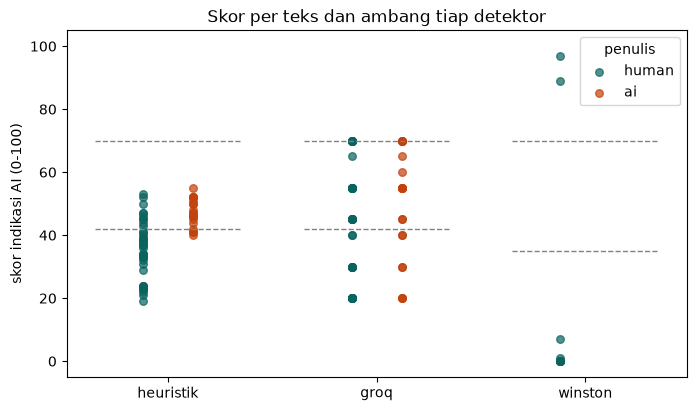

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
names = list(scores.detector.unique())
for x, name in enumerate(names):
    group = scores[scores.detector == name]
    for label, color, offset in (("human", "#0B635F", -0.12), ("ai", "#C2410C", 0.12)):
        part = group[group.label == label]
        ax.scatter([x + offset] * len(part), part.score, color=color, s=30, alpha=0.7, label=label if x == 0 else None)
    for threshold in BANDS[name]:
        ax.hlines(threshold, x - 0.35, x + 0.35, colors="grey", linestyles="dashed", linewidth=1)
ax.set_xticks(range(len(names)), names)
ax.set_ylabel("skor indikasi AI (0-100)")
ax.set_ylim(-5, 105)
ax.legend(title="penulis")
ax.set_title("Skor per teks dan ambang tiap detektor")
kit.save_figure(fig, "e1_conversation_skor_per_detektor.png")
plt.show()

In [9]:
bands = scores.pivot(index="id", columns="detector", values="band")
reasons = scores.pivot(index="id", columns="detector", values="reasons")
accused = bands[(essays.set_index("id").label.reindex(bands.index) == "human") & bands.ne("rendah").any(axis=1)]
print(f"{len(accused)} dari {len(humans)} potongan manusia dituduh oleh minimal satu detektor.")
accused.join(reasons[["heuristik", "groq"]].add_suffix(" (alasan)"))

36 dari 40 potongan manusia dituduh oleh minimal satu detektor.


detector,groq,heuristik,winston,heuristik (alasan),groq (alasan)
id,,,,,
H01a,rendah,rendah,tinggi,Keseragaman kalimat +14.9; Keragaman kosakata +12.5,contoh konkret pengalaman pribadi; variasi panjang kalimat; bahasa...
H01b,tinggi,sedang,NaN,Keseragaman kalimat +23.3; Keragaman kosakata +12.5,panjang kalimat seragam tanpa variasi; tidak ada contoh konkret; t...
H02b,rendah,rendah,NaN,Keseragaman kalimat +18.6; Keragaman kosakata +12.5,kalimat panjang seragam tanpa variasi; tidak ada contoh konkret at...
H03b,rendah,rendah,NaN,Keseragaman kalimat +19.9; Keragaman kosakata +10.6,menyertakan data spesifik (upah minimum 2017); menyebutkan contoh ...
H04b,sedang,sedang,NaN,Keseragaman kalimat +29.9; Keragaman kosakata +12.5,panjang kalimat seragam tanpa variasi; tidak ada contoh konkret; t...
H05a,tinggi,rendah,rendah,Keseragaman kalimat +13.6; Keragaman kosakata +12.5,tidak ada contoh konkret; klaim seimbang tanpa pendirian; tidak ad...
H05b,rendah,rendah,NaN,Keragaman kosakata +12.5; Keseragaman kalimat +11.8,menyertakan data spesifik PISA 2015; penalaran sebab-akibat; bahas...
H06a,sedang,rendah,rendah,Keragaman kosakata +12.5; Kepastian datar +5.0,panjang kalimat seragam tanpa variasi; tidak ada contoh konkret at...
H06b,sedang,rendah,NaN,Keseragaman kalimat +15.4; Keragaman kosakata +12.5,tidak ada contoh konkret atau referensi spesifik; kalimat bersifat...


## 5. Kesimpulan

Ringkasan disimpan ke `results/e1_esai_conversation/`. Berkas CSV hanya berisi id dan angka, tanpa teks artikel (lisensi CC BY-ND).

In [10]:
per_essay.to_csv(OUT / "per_esai.csv")
decision.to_csv(OUT / "aturan_keputusan.csv", index=False)
same_decision.to_csv(OUT / "aturan_keputusan_teks_winston.csv", index=False)

kit.write_summary(OUT / "ringkasan.md", "E1 lanjutan: salah tuduh pada 40 potongan tulisan manusia", {
    "Data": f"{len(humans)} potongan manusia dari 20 artikel The Conversation Indonesia (2017-2019), "
            f"{(essays.label == 'ai').sum()} esai AI ({', '.join(GEN_MODELS)}). Semua teks {MIN_WORDS}-{MAX_WORDS} kata.",
    "Aturan keputusan, semua teks": kit.md_table(decision),
    f"Aturan keputusan, {len(winston_ids)} teks yang juga dinilai Winston": kit.md_table(same_decision),
    "AUC dan waktu": kit.md_table(overview),
    "Batasan": "- Tulisan manusia berasal dari akademisi dan sudah disunting redaksi, lebih rapi daripada esai mahasiswa.\n"
               "- Dua potongan dari artikel yang sama tidak sepenuhnya independen.\n"
               "- Winston hanya menilai sebagian teks karena kredit terbatas.\n"
               "- Ambang 42/70 untuk Groq dipinjam dari heuristik, belum dikalibrasi.",
})
print((OUT / "ringkasan.md").read_text())

# E1 lanjutan: salah tuduh pada 40 potongan tulisan manusia

## Data

40 potongan manusia dari 20 artikel The Conversation Indonesia (2017-2019), 20 esai AI (openai/gpt-oss-20b, qwen/qwen3.8-27b). Semua teks 100-200 kata.

## Aturan keputusan, semua teks

| detektor | aturan | FPR | TPR |
|---|---|---|---|
| groq | tinggi (skor 70+) | 7/40 [9%-32%] | 4/20 [8%-42%] |
| groq | sedang ke atas (skor 42+) | 23/40 [42%-71%] | 13/20 [43%-82%] |
| heuristik | tinggi (skor 70+) | 0/40 [0%-9%] | 0/20 [0%-16%] |
| heuristik | sedang ke atas (skor 42+) | 10/40 [14%-40%] | 17/20 [64%-95%] |
| winston | tinggi (skor 70+) | 2/13 [4%-42%] | - |
| winston | sedang ke atas (skor 35+) | 2/13 [4%-42%] | - |

## Aturan keputusan, 13 teks yang juga dinilai Winston

| detektor | aturan | FPR | TPR |
|---|---|---|---|
| groq | tinggi (skor 70+) | 2/13 [4%-42%] | - |
| groq | sedang ke atas (skor 42+) | 7/13 [29%-77%] | - |
| heuristik | tinggi (skor 70+) | 0/13 [0%-23%] | - |
| heuristik | sedang ke atas (sko